# 📘 Notebook 01: What Is a Hyperparameter, and How Do We Choose One Honestly?

### Course: *From Defaults to Decisions: Hyperparameters, Explained by Experiment*
**Instructor:** Ioannis Tsioulis

---

> 💡 **This notebook is already run.** Every number and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** Every experiment in this course trains small networks on 10,000 Fashion-MNIST images, so that a whole comparison takes seconds to minutes on an ordinary processor; this notebook takes about **ten minutes** in total. The **values** we find (the best learning rate, the best number of epochs) belong to this dataset and this model; the **lessons** about how each hyperparameter behaves carry over, but the numbers must be re-checked on every new problem. That is the whole point of the course.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Tell **parameters** (learned by training) from **hyperparameters** (chosen by you)
- Explain why we need **three** sets of data: training, validation and test
- Show, with an experiment, that choosing among many settings on the validation set makes the validation score **optimistic**
- Explain why the **test set** must be used only once, at the very end
- Measure how much results change with the **random seed**, and why that matters before comparing settings

> **Prerequisites:** a first neural network in PyTorch, as in [From Python to Deep Learning and Fine-Tuning](https://giannis00.github.io/teaching/#deep-learning).
>
> 🔭 **Why this notebook matters:** every course on neural networks says "set the learning rate to 0.001 and train for 20 epochs". Why those numbers? What happens with others? This course answers by **experiment**: one hyperparameter at a time, same data, same model, and a comment on every result. Before any of that, we need an honest way to compare settings, which is what this first notebook builds.

## 1. Parameters and hyperparameters

### Intuition first
A neural network has two kinds of numbers:
- **Parameters** (the weights and biases): there are thousands or millions of them, and **training** finds them automatically by gradient descent.
- **Hyperparameters**: the choices you make **before** training: how many layers and neurons, which activation function, the learning rate, the batch size, how many epochs, how much dropout. Gradient descent cannot learn them, either because they are not numbers you can differentiate (the number of layers) or because they control the training itself (the learning rate).

Choosing hyperparameters is like choosing the recipe and the oven temperature; training is the baking. A bad recipe cannot be rescued by baking longer.

## 2. The shared setup

Every notebook in this course starts with the same cell: **Fashion-MNIST** (pictures of clothes, 10 classes), split into **10,000 training images**, **5,000 validation images** and the official **10,000 test images**; a function `make_mlp` that builds a fully connected network; and a function `fit` that trains it and records, after every epoch, the loss and accuracy on the training and validation data.

In [1]:
# Shared setup: the same data, model builder and training loop in every notebook of this course.
import warnings
warnings.filterwarnings("ignore")

import gzip, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 3)

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)

images = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
labels = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X_test = torch.tensor(read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
mean, std = images.mean(), images.std()
images, X_test = (images - mean) / std, (X_test - mean) / std

order = torch.randperm(len(images), generator=torch.Generator().manual_seed(0))
X_train, y_train = images[order[:10000]], labels[order[:10000]]       # 10,000 images to learn from
X_val, y_val = images[order[10000:15000]], labels[order[10000:15000]] # 5,000 to choose hyperparameters
print(f"train {len(X_train):,}   validation {len(X_val):,}   test {len(X_test):,}")

def make_mlp(hidden=(128,), activation=nn.ReLU, dropout=0.0, batchnorm=False):
    layers, width = [], 784
    for h in hidden:
        layers.append(nn.Linear(width, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(activation())
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = h
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def fit(model, epochs=20, lr=1e-3, batch=128, optimizer="adam", weight_decay=0.0, scheduler=None, seed=0, X=None, y=None):
    """Train and return a history with one row per epoch."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    torch.manual_seed(seed)
    opts = {"sgd": lambda p: torch.optim.SGD(p, lr=lr, weight_decay=weight_decay),
            "momentum": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay),
            "rmsprop": lambda p: torch.optim.RMSprop(p, lr=lr, weight_decay=weight_decay),
            "adam": lambda p: torch.optim.Adam(p, lr=lr, weight_decay=weight_decay),
            "adamw": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay)}
    opt = opts[optimizer](model.parameters())
    steps_per_epoch = (len(X) + batch - 1) // batch
    sched = scheduler(opt, epochs * steps_per_epoch) if scheduler else None
    rows, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        total = 0.0
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched:
                sched.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(X_val), y_val).item()
        rows.append({"epoch": epoch, "train loss": total / len(X), "val loss": val_loss,
                     "train acc": accuracy(model, X, y), "val acc": accuracy(model, X_val, y_val)})
    history = pd.DataFrame(rows).set_index("epoch")
    history.attrs["seconds"] = time.time() - start
    return history

train 10,000   validation 5,000   test 10,000


In [2]:
model = make_mlp(hidden=(128,))
weights = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nparameters (learned by training): {weights:,}")
print("hyperparameters (chosen by us) in this run: 1 hidden layer, 128 neurons, ReLU, Adam, lr 0.001, batch 128, 20 epochs")
history = fit(model, epochs=20)
history.iloc[[0, 4, 9, 19]].round(3)

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=10, bias=True)
)

parameters (learned by training): 101,770
hyperparameters (chosen by us) in this run: 1 hidden layer, 128 neurons, ReLU, Adam, lr 0.001, batch 128, 20 epochs


,train loss,val loss,train acc,val acc
epoch,,,,
1,0.766,0.541,0.809,0.807
5,0.385,0.457,0.860,0.834
10,0.285,0.412,0.898,0.851
20,0.169,0.418,0.947,0.856


**What we see.** The network has **101,770 parameters** (784 × 128 weights into the hidden layer, 128 × 10 into the output, plus the biases), all found by training. The hyperparameters fit in one line, and we chose every one of them. The history already tells a story that the next notebooks will explain: training accuracy keeps rising (to **94.7%** after 20 epochs) while validation accuracy stops improving around **85 to 86%**, and the validation loss is lower at epoch 10 (0.412) than at epoch 20 (0.418). The network is starting to memorise the training images.

## 3. Why three sets of data?

- The **training set** is what the network learns from. Its accuracy is always too optimistic: the network has seen these images.
- The **validation set** is used to **choose** hyperparameters: we train with several settings and keep the one with the best validation score.
- The **test set** is used **once**, at the end, to report how well the final choice works on images that played no part in any decision.

Why not choose on the test set directly? Because **choosing is a form of learning**. If we try many settings and keep the best on some data, that data has influenced the result, and its score is no longer an honest estimate. The next experiment shows this happening.

### An experiment: choosing among 30 random settings

We train 30 networks with **random** hyperparameters (width, learning rate, batch size, epochs), keep the one with the best **validation** accuracy, and compare its validation score with its **test** score.

In [3]:
rng = np.random.default_rng(0)
results = []
start = time.time()
for trial in range(30):
    setting = {"width": int(rng.choice([32, 64, 128, 256])), "lr": float(10 ** rng.uniform(-4, -1.5)),
               "batch": int(rng.choice([32, 64, 128, 256])), "epochs": int(rng.integers(3, 15))}
    model = make_mlp(hidden=(setting["width"],))
    h = fit(model, epochs=setting["epochs"], lr=setting["lr"], batch=setting["batch"], seed=trial)
    results.append({**setting, "val acc": h["val acc"].iloc[-1], "test acc": accuracy(model, X_test, y_test)})
results = pd.DataFrame(results).sort_values("val acc", ascending=False)
print(f"30 trainings in {time.time() - start:.0f} s")
results.head(5).round(4)

30 trainings in 306 s


,width,lr,batch,epochs,val acc,test acc
2,128,3.300e-03,256,14,0.857,0.849
3,128,2.300e-03,128,14,0.856,0.854
12,256,9.000e-04,128,13,0.854,0.849
7,128,6.000e-04,64,8,0.854,0.843
16,128,6.000e-04,128,11,0.852,0.848


best setting by validation: val acc 0.8568, test acc 0.8486, gap 0.82 points
average over all 30 settings: val acc 0.8281, test acc 0.8228, gap 0.54 points


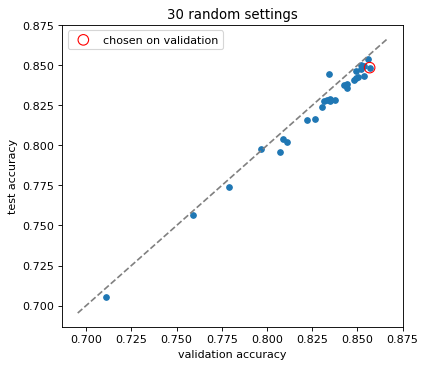

In [4]:
best = results.iloc[0]
print(f"best setting by validation: val acc {best['val acc']:.4f}, test acc {best['test acc']:.4f}, "
      f"gap {100 * (best['val acc'] - best['test acc']):.2f} points")
print(f"average over all 30 settings: val acc {results['val acc'].mean():.4f}, test acc {results['test acc'].mean():.4f}, "
      f"gap {100 * (results['val acc'].mean() - results['test acc'].mean()):.2f} points")

plt.figure(figsize=(5.5, 5))
plt.scatter(results["val acc"], results["test acc"], s=25)
lo, hi = results[["val acc", "test acc"]].min().min() - 0.01, results[["val acc", "test acc"]].max().max() + 0.01
plt.plot([lo, hi], [lo, hi], "--", color="grey")
plt.scatter([best["val acc"]], [best["test acc"]], s=90, facecolors="none", edgecolors="red", label="chosen on validation")
plt.xlabel("validation accuracy"); plt.ylabel("test accuracy"); plt.legend()
plt.title("30 random settings")
plt.show()

**What we see.** Of the 30 random settings, the winner on validation reached **85.7%** validation accuracy but **84.9%** on the test set: a gap of **0.82** points. Part of that gap is not caused by choosing: on average over **all** 30 settings, validation is **0.54** points above test, because our validation images come from the official training file and the test images from a separate file collected slightly differently. The rest, about **0.3 points**, is the optimism of picking a winner. In the plot, the circled winner sits to the right of the crowd, but not above it on the test axis: it was partly lucky on the validation set.

The effect is small here because we tried only 30 settings on 5,000 validation images. With hundreds of settings, or small validation sets, it grows; this is why the test set must be kept for the very end.

## 4. How much does luck matter?

Two runs with the **same** hyperparameters differ, because the starting weights and the order of the images are random (the **seed**). Before claiming that one setting beats another, we must know how big these random differences are.

In [5]:
seeds = []
for seed in range(8):
    h = fit(make_mlp(hidden=(128,)), epochs=20, seed=seed)
    seeds.append(h["val acc"].iloc[-1])
seeds = np.array(seeds)
print("validation accuracy over 8 seeds:", np.round(seeds, 4))
print(f"mean {seeds.mean():.4f}, standard deviation {seeds.std():.4f}, range {100 * (seeds.max() - seeds.min()):.2f} points")

validation accuracy over 8 seeds: [0.8526 0.8572 0.8554 0.8658 0.8594 0.8494 0.86   0.8598]
mean 0.8575, standard deviation 0.0047, range 1.64 points


**What we see.** The **same** setting, trained with 8 different seeds, gives validation accuracies from **84.9%** to **86.6%**: a range of **1.6 points**, with a standard deviation of about **0.5 points**. Any difference between two settings smaller than about one point could be luck. In the following notebooks, when differences are small, we repeat runs with several seeds before drawing conclusions.

## ⚠️ Common pitfalls

- **Tuning on the test set.** Every decision made by looking at test results leaks information; the final test score is then optimistic.
- **Reporting the best validation score as the expected performance.** It is the winner of a contest and is biased upwards; report the test score of the chosen model.
- **Comparing two settings with one run each.** A difference smaller than the seed-to-seed spread may be pure luck.
- **Changing several hyperparameters at once and crediting one.** In this course we change one at a time, for exactly this reason.
- **Using a tiny validation set.** With 50 images, one image is 2 percentage points; small validation sets make choices noisy.

## ✏️ Exercises

### Exercise 1 (Validation size)
Repeat the seed experiment, but measure each model on only the **first 500** validation images. How much larger is the spread of the scores? What does that mean for choosing hyperparameters with a small validation set?

In [6]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
small = []
for seed in range(8):
    m = make_mlp(hidden=(128,))
    fit(m, epochs=20, seed=seed)
    small.append(accuracy(m, X_val[:500], y_val[:500]))
small = np.array(small)
print(f"500 images: std {small.std():.4f}, range {100 * (small.max() - small.min()):.2f} points")
```

*With a tenth of the validation images, the measurement itself becomes noisy: the same models now look further apart. A choice between two settings that differ by less than this spread is a coin toss.*
</details>

### Exercise 2 (K-fold cross-validation)
With little data, a fixed validation set wastes images. Use 5-fold cross-validation on the 10,000 training images (train on 8,000, validate on 2,000, five times) to estimate the accuracy of the default model. Compare the mean with the single validation score.

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
folds = torch.arange(10000).chunk(5)
scores = []
for k, val_idx in enumerate(folds):
    train_idx = torch.cat([f for j, f in enumerate(folds) if j != k])
    m = make_mlp(hidden=(128,))
    fit(m, epochs=20, X=X_train[train_idx], y=y_train[train_idx])
    scores.append(accuracy(m, X_train[val_idx], y_train[val_idx]))
print("5-fold accuracies:", np.round(scores, 4), " mean", round(float(np.mean(scores)), 4))
```

*Every image is used for validation once and for training four times, and the five scores show the uncertainty directly. Cross-validation costs five trainings instead of one, so it is used mainly when data is scarce.*
</details>

## 🔑 Key takeaways

- **Parameters** are learned by training; **hyperparameters** are chosen by you, before training.
- Use a **training** set to learn, a **validation** set to choose, and a **test** set once, at the end.
- Choosing the best of many settings on the validation set makes its score **optimistic**; the test set gives the honest estimate.
- Measure the **seed-to-seed** spread before believing that one setting beats another.

---
**Next:** *Notebook 02: Epochs and Early Stopping*, the first hyperparameter: how long to train.

---
*© Ioannis Tsioulis. *From Defaults to Decisions: Hyperparameters, Explained by Experiment*. Prepared for educational use.*